In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("NetFlix.csv")

In [3]:
df.head()

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,14-Aug-20,2020,TV-MA,4,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s10,Movie,1920,Vikram Bhatt,"Rajneesh Duggal, Adah Sharma, Indraneil Sengup...",India,15-Dec-17,2008,TV-MA,143,"Horror Movies, International Movies, Thrillers",An architect and his wife move into a castle t...
2,s100,Movie,3 Heroines,Iman Brotoseno,"Reza Rahadian, Bunga Citra Lestari, Tara Basro...",Indonesia,5-Jan-19,2016,TV-PG,124,"Dramas, International Movies, Sports Movies",Three Indonesian women break records by becomi...
3,s1000,Movie,Blue Mountain State: The Rise of Thadland,Lev L. Spiro,"Alan Ritchson, Darin Brooks, James Cade, Rob R...",United States,1-Mar-16,2016,R,90,Comedies,New NFL star Thad buys his old teammates' belo...
4,s1001,TV Show,Blue Planet II,NaN,David Attenborough,United Kingdom,3-Dec-18,2017,TV-G,1,"British TV Shows, Docuseries, Science & Nature TV",This sequel to the award-winning nature series...


In [4]:
df.shape

(7787, 12)

In [5]:
df.columns

Index(['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added',
       'release_year', 'rating', 'duration', 'genres', 'description'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7787 entries, 0 to 7786
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       7787 non-null   object
 1   type          7787 non-null   object
 2   title         7787 non-null   object
 3   director      5398 non-null   object
 4   cast          7069 non-null   object
 5   country       7280 non-null   object
 6   date_added    7777 non-null   object
 7   release_year  7787 non-null   int64 
 8   rating        7780 non-null   object
 9   duration      7787 non-null   int64 
 10  genres        7787 non-null   object
 11  description   7787 non-null   object
dtypes: int64(2), object(10)
memory usage: 730.2+ KB


# Data Cleaning

In [7]:
df.isnull().sum()

show_id            0
type               0
title              0
director        2389
cast             718
country          507
date_added        10
release_year       0
rating             7
duration           0
genres             0
description        0
dtype: int64

## Checking Dupicate Records

In [8]:
df.duplicated().sum()

np.int64(0)

### Observation:
No duplicate records were found in the dataset.

# Handling Missing Values

In [9]:
df[['director', 'cast', 'country', 'date_added', 'rating']].isnull().sum()

director      2389
cast           718
country        507
date_added      10
rating           7
dtype: int64

The dataset contains missing values in multiple column as shown above.
There missing values needs to be handled before further analysis.

In [10]:
df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna('Unknown')

## Verifying Cleaned Columns

In [11]:
df[['director', 'cast', 'country']].isnull().sum()

director    0
cast        0
country     0
dtype: int64

## Removing rows with small missing values

In [12]:
df= df.dropna(subset=['date_added', 'rating'])

## Final Missing Values Check

In [13]:
df.isnull().sum()

show_id         0
type            0
title           0
director        0
cast            0
country         0
date_added      0
release_year    0
rating          0
duration        0
genres          0
description     0
dtype: int64

## Checking Data Types

In [14]:
df.dtypes

show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration         int64
genres          object
description     object
dtype: object

## Converting Date Columns

In [15]:
df = df.copy()
df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')

C:\Users\Admin\AppData\Local\Temp\ipykernel_13496\4194282176.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df['date_added'] = pd.to_datetime(df['date_added'], errors='coerce')


In [16]:
df.dtypes

show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                 int64
genres                  object
description             object
dtype: object

### Observation
The 'date_added'column was successfully converted from object type to datetime format for easier time based analysis and visualization.

## Cleaned Dataset Perview

In [17]:
df.head(10)

,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,genres,description
0,s1,TV Show,3%,Unknown,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,2020-08-14,2020,TV-MA,4,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s10,Movie,1920,Vikram Bhatt,"Rajneesh Duggal, Adah Sharma, Indraneil Sengup...",India,2017-12-15,2008,TV-MA,143,"Horror Movies, International Movies, Thrillers",An architect and his wife move into a castle t...
2,s100,Movie,3 Heroines,Iman Brotoseno,"Reza Rahadian, Bunga Citra Lestari, Tara Basro...",Indonesia,2019-01-05,2016,TV-PG,124,"Dramas, International Movies, Sports Movies",Three Indonesian women break records by becomi...
3,s1000,Movie,Blue Mountain State: The Rise of Thadland,Lev L. Spiro,"Alan Ritchson, Darin Brooks, James Cade, Rob R...",United States,2016-03-01,2016,R,90,Comedies,New NFL star Thad buys his old teammates' belo...
4,s1001,TV Show,Blue Planet II,Unknown,David Attenborough,United Kingdom,2018-12-03,2017,TV-G,1,"British TV Shows, Docuseries, Science & Nature TV",This sequel to the award-winning nature series...
5,s1002,Movie,Blue Ruin,Jeremy Saulnier,"Macon Blair, Devin Ratray, Amy Hargreaves, Kev...","United States, France",2019-02-25,2013,R,90,"Independent Movies, Thrillers",Bad news from the past unhinges vagabond Dwigh...
6,s1003,Movie,Blue Streak,Les Mayfield,"Martin Lawrence, Luke Wilson, Peter Greene, Da...","Germany, United States",2021-01-01,1999,PG-13,94,"Action & Adventure, Comedies",A jewel thief returns to his hiding place afte...
7,s1004,Movie,Blue Valentine,Derek Cianfrance,"Ryan Gosling, Michelle Williams, Faith Wladyka...",United States,2018-07-05,2010,R,112,"Dramas, Independent Movies, Romantic Movies",As Cindy and Dean muddle through their languis...
8,s1005,Movie,BluffMaster!,Rohan Sippy,"Abhishek Bachchan, Priyanka Chopra, Riteish De...",India,2021-01-08,2005,TV-14,129,"Comedies, International Movies, Romantic Movies",When his girlfriend learns the truth about his...
9,s1006,Movie,Blurred Lines: Inside the Art World,Barry Avrich,Unknown,Canada,2017-12-31,2017,TV-MA,85,Documentaries,Artists and industry insiders shed light on th...


# Exploratory Data Analysis (EDA)

## Movies vs TV Shows DIstribution

In [18]:
df['type'].value_counts()

type
Movie      5372
TV Show    2398
Name: count, dtype: int64

### Observation
The dataset contains more movies than tv shows. Movies makeup the most of the contents available on Netflix.

## Visualizatin of Content Types

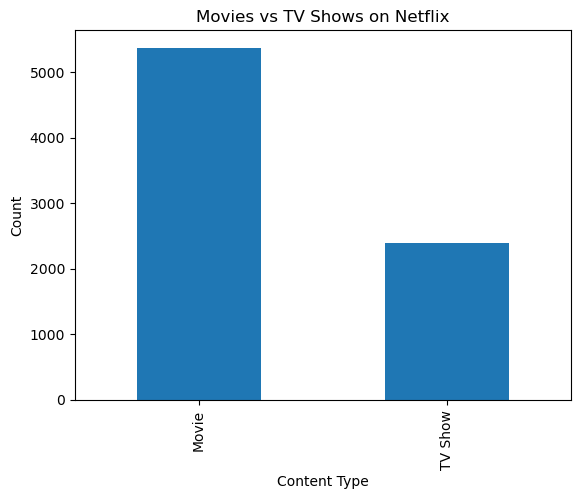

In [19]:
df['type'].value_counts().plot(kind='bar')

plt.title("Movies vs TV Shows on Netflix")
plt.xlabel("Content Type")
plt.ylabel("Count")

plt.show()

## Most Common Content Ratings

In [20]:
df['rating'].value_counts()

rating
TV-MA       2861
TV-14       1928
TV-PG        804
R            665
PG-13        386
TV-Y         279
TV-Y7        270
PG           247
TV-G         194
NR            83
G             39
TV-Y7-FV       6
UR             5
NC-17          3
Name: count, dtype: int64

### Observation
The common rating in dataset is TV-MA with 2861 entries, indicating that a large portion of Netflix content is intended for mature audience.

## Content Release Trend Over the Years

In [21]:
df['release_year'].value_counts().sort_index()

release_year
1925       1
1942       2
1943       3
1944       3
1945       3
        ... 
2017    1010
2018    1120
2019     996
2020     868
2021      31
Name: count, Length: 73, dtype: int64

## Visualization of Release Trend

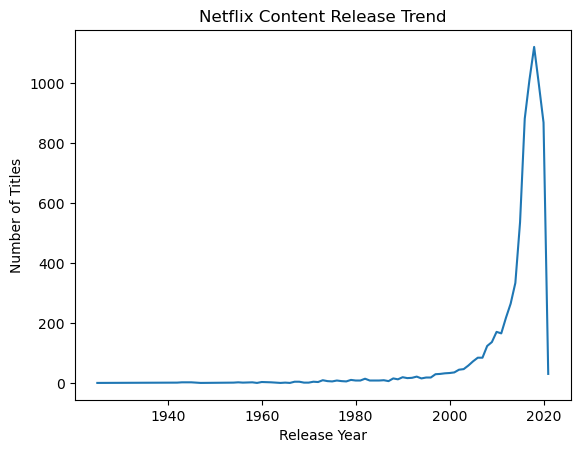

In [22]:
df['release_year'].value_counts().sort_index().plot(kind='line')

plt.title("Netflix Content Release Trend")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")

plt.show()

## Most Popular Genres on Netflix

In [23]:
df['genres'].value_counts().head(10)

genres
Documentaries                                       334
Stand-Up Comedy                                     321
Dramas, International Movies                        320
Comedies, Dramas, International Movies              243
Dramas, Independent Movies, International Movies    215
Kids' TV                                            204
Children & Family Movies                            177
Documentaries, International Movies                 172
Children & Family Movies, Comedies                  169
Comedies, International Movies                      161
Name: count, dtype: int64

### Observation
Documentaries and Stand-Up Comedy are among the most common genres Netflix. International movies also appear frequently, showing Netflix's strong focus on global content.

## Visualization of Top Genres

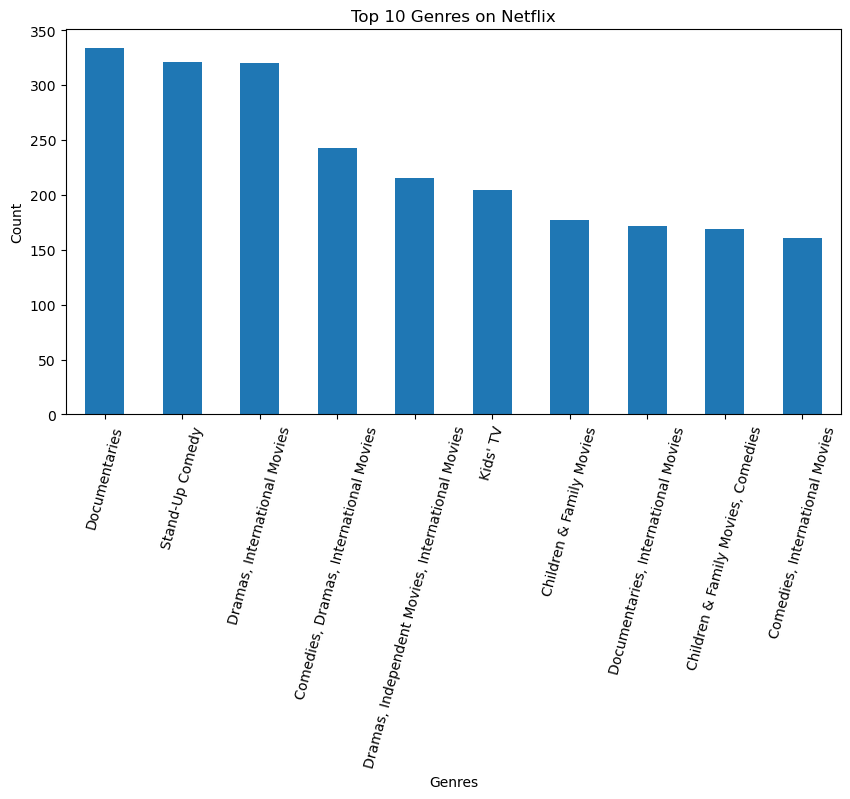

In [24]:
plt.figure(figsize=(10, 5))

df['genres'].value_counts().head(10).plot(kind='bar')

plt.title("Top 10 Genres on Netflix")
plt.xlabel("Genres")
plt.ylabel("Count")

plt.xticks(rotation=75)

plt.show()

## Movies vs TV Shows Analysis

In [25]:
df['type'].value_counts()

type
Movie      5372
TV Show    2398
Name: count, dtype: int64

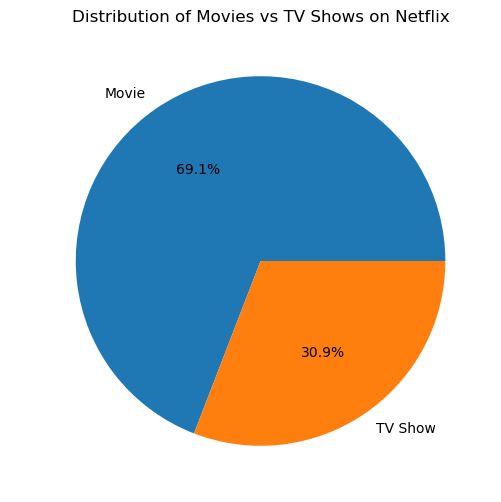

In [26]:
df['type'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(6,6))

plt.title("Distribution of Movies vs TV Shows on Netflix")
plt.ylabel(" ")

plt.show()

## Top Countries Producig Netflix Content

In [27]:
df['country'].value_counts().head(10)

country
United States     2546
India              923
Unknown            505
United Kingdom     396
Japan              224
South Korea        183
Canada             177
Spain              134
France             115
Egypt              101
Name: count, dtype: int64

### Observation
The Untied States contributes the highest number of Netflix titles, followed by India and the United Kingdom. A noticable number of entries are marked as "Unknown", indicating mising countries data in the dataset.

## Top 10 Countries Producing Netflix Content (Visualization)

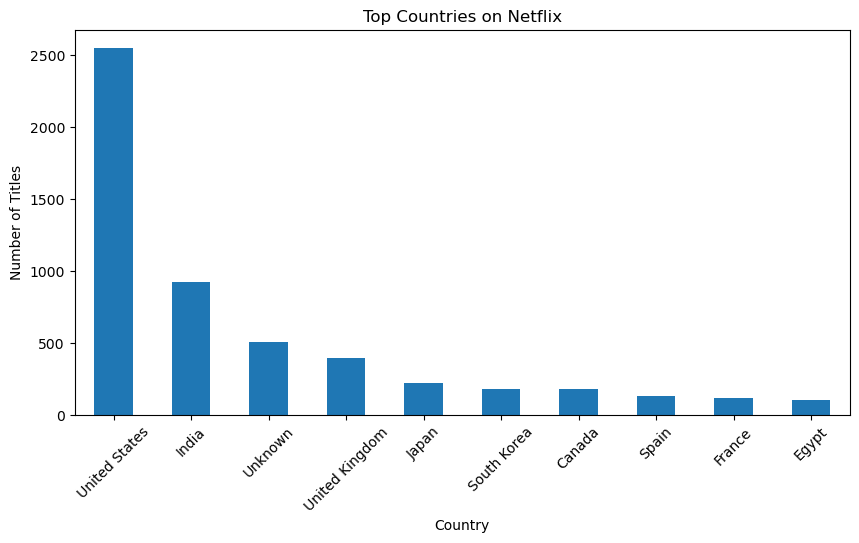

In [28]:
df['country'].value_counts().head(10).plot(kind='bar', figsize=(10, 5))

plt.title("Top Countries on Netflix")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

## Top Directors on Netflix

In [29]:
df['director'].value_counts().head(10)

director
Unknown                   2376
Raúl Campos, Jan Suter      18
Marcus Raboy                16
Jay Karas                   14
Cathy Garcia-Molina         13
Martin Scorsese             12
Jay Chapman                 12
Youssef Chahine             12
Steven Spielberg            10
David Dhawan                 9
Name: count, dtype: int64

In [30]:
df[df['director'] != 'Unknown']['director'].value_counts().head(10)

director
Raúl Campos, Jan Suter    18
Marcus Raboy              16
Jay Karas                 14
Cathy Garcia-Molina       13
Youssef Chahine           12
Jay Chapman               12
Martin Scorsese           12
Steven Spielberg          10
David Dhawan               9
Ryan Polito                8
Name: count, dtype: int64

### Observation
A large number of entries have missing director information marked as 'Unknown'. After excluding 'Unknown' values, directors like Raúl Compos, Jan Sutar and Marcus Raboy appears most frequently in the dataset. However, most directors relatively have low counts, showing that Netflix content is distributed cross many creators rather than dominating by a single director.

## Top Directors (Excluding Unknown)

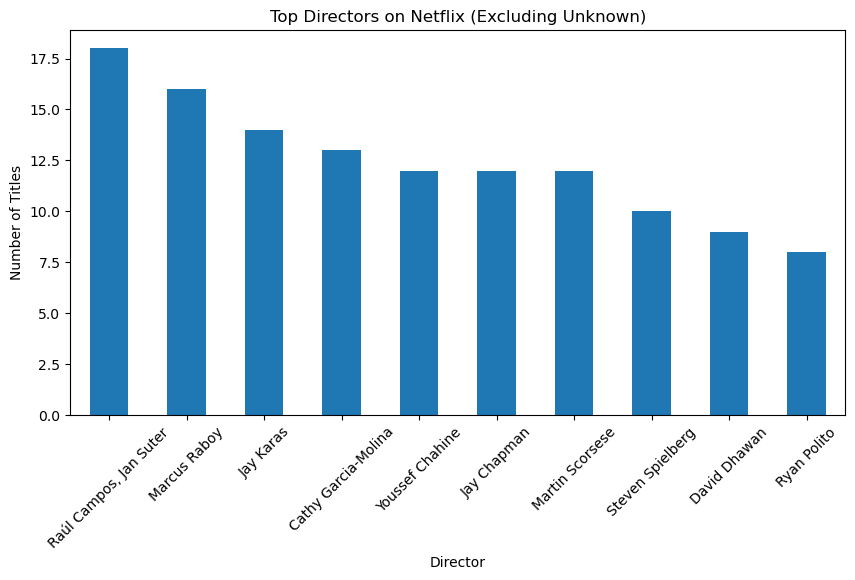

In [31]:
df[df['director'] != 'Unknown']['director'].value_counts().head(10).plot(kind='bar',figsize=(10,5))

plt.title("Top Directors on Netflix (Excluding Unknown)")
plt.xlabel("Director")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)

plt.show()

## Movies vs TV Shows Over the Years

In [32]:
df.groupby(['release_year', 'type']).size().unstack().fillna(0)

type,Movie,TV Show
release_year,,
1925,0.0,1.0
1942,2.0,0.0
1943,3.0,0.0
1944,3.0,0.0
1945,3.0,0.0
...,...,...
2017,742.0,268.0
2018,734.0,386.0
2019,582.0,414.0


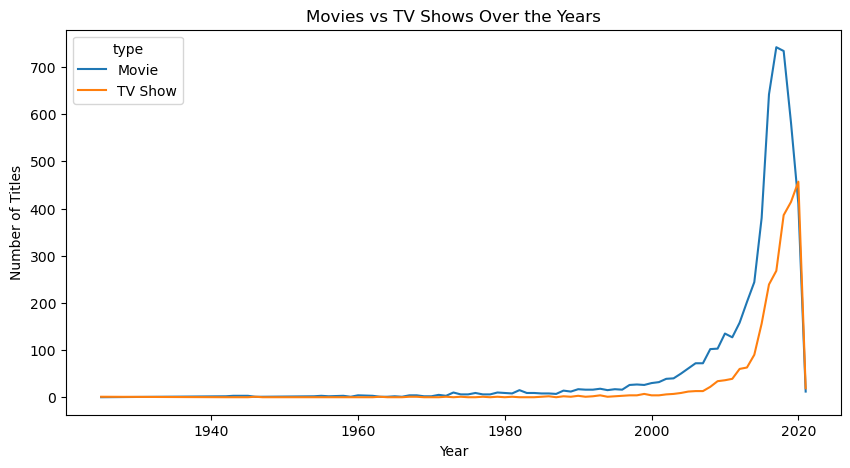

In [33]:
df.groupby(['release_year', 'type']).size().unstack().fillna(0).plot(figsize=(10,5))

plt.title("Movies vs TV Shows Over the Years")
plt.xlabel("Year")
plt.ylabel("Number of Titles")

plt.show()

### Observation 
Netflix content production increased rapidly after 2010. Movies dominated the platform throughout most years, while TV shows also experienced steady growth overtime.

# Conclusion

This project explored the Netflix dataset through the data cleaning, preprocessing and exploratory data analysis (EDA).

Key insights from the analysis nclude:

- Movies are more common on Netflix than TV Shows.
- TV-MA is the most frequent content rating, showing a strong presence of mature audience content.
- Netflix content production increased significantly after 2010.
- Documentaries and International Movies are among the most popular genres.
- The United Staes contributes highest amount of Netflix content, followed by India and the United Kingdom.
- Movies consistently outnumber TV Shows across most years.

Overall, the project demonstrates how Python libraries such as Pandas and Matplotlib can be used for data cleaning, visualization, and extracting meaningful insights from real-world datasets.